# SmartMovie — Étape 5 : NLP avec TF-IDF sur `overview`

Objectif : transformer le synopsis (`overview`) de chaque film en représentation numérique exploitable (TF-IDF), en testant l'effet de `max_features` et `ngram_range` sur la matrice résultante et sur les termes qu'elle met en avant.


## 1. Chargement des données depuis MongoDB

In [12]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient
from dotenv import load_dotenv
from sklearn.feature_extraction.text import TfidfVectorizer

load_dotenv()
sns.set_theme(style="whitegrid")

MONGO_URI = os.getenv("MONGO_URI")
client = MongoClient(MONGO_URI)
db = client["smartmovie"]
collection = db["movies"]

df = pd.DataFrame(list(collection.find({}, {"_id": 0, "movie_id": 1, "title": 1, "overview": 1})))
print(f"{len(df)} films chargés")
df.head()


931 films chargés


,movie_id,overview,title
0,969681,Fighting crime full-time as Spider-Man in a wo...,Spider-Man: Brand New Day
1,1423191,Medical courier Bryan unwittingly finds himsel...,Resident Evil
2,1368337,"Odysseus, the legendary King of Ithaca, embark...",The Odyssey
3,1751701,"After losing his father, Ethan Nichols inherit...",After Impact
4,1084244,When Bonnie receives a Lilypad tablet as a gif...,Toy Story 5


## 2. Traitement des valeurs manquantes

On regarde combien de synopsis sont manquants ou vides avant de décider quoi en faire.

**Choix retenu** : on garde toutes les lignes (pour ne pas perdre des films utiles pour les autres étapes du projet) mais on remplace les `overview` manquants par une chaîne vide `""`. Conséquence assumée : `TfidfVectorizer` produira un vecteur nul (toutes les valeurs à 0) pour ces films — ils n'auront simplement aucun terme actif, ce qui est le comportement correct plutôt que d'inventer un contenu. On garde une colonne `has_overview` pour pouvoir filtrer ou pondérer ces cas plus tard si besoin (ex. les exclure d'un système de recommandation basé uniquement sur le texte).


In [13]:
n_missing = df["overview"].isna().sum()
n_empty = (df["overview"].fillna("").str.strip() == "").sum()
print(f"Synopsis manquants (NaN) : {n_missing}")
print(f"Synopsis vides ou manquants au total : {n_empty} / {len(df)}")

df["has_overview"] = df["overview"].fillna("").str.strip().ne("").astype(int)
df["overview"] = df["overview"].fillna("")


Synopsis manquants (NaN) : 0
Synopsis vides ou manquants au total : 3 / 931


## 3. Nettoyage du texte

Étapes de nettoyage appliquées, dans l'ordre :
1. Mise en minuscules — pour que "Action" et "action" soient traités comme le même mot.
2. Suppression des caractères non alphabétiques (chiffres, ponctuation) — ils n'apportent pas de sens thématique pour ce cas d'usage.
3. Suppression des espaces multiples résiduels.

On ne fait **pas** de lemmatisation/stemming ici pour garder le pipeline simple et dépendance-light (pas de téléchargement de corpus NLTK) ; `TfidfVectorizer` gèrera la suppression des stop words anglais directement via son paramètre `stop_words="english"`, ce qui est suffisant pour ce dataset (synopsis en anglais, `language=en-US` demandé à l'API TMDB).


In [14]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["overview_clean"] = df["overview"].apply(clean_text)

# Exemple avant / après
df[["overview", "overview_clean"]].head(3)


,overview,overview_clean
0,Fighting crime full-time as Spider-Man in a wo...,fighting crime full time as spider man in a wo...
1,Medical courier Bryan unwittingly finds himsel...,medical courier bryan unwittingly finds himsel...
2,"Odysseus, the legendary King of Ithaca, embark...",odysseus the legendary king of ithaca embarks ...


## 4. TF-IDF — baseline

On commence par une vectorisation TF-IDF "par défaut" (suppression des stop words anglais, pas de limite de vocabulaire) pour avoir une référence.


In [15]:
tfidf_baseline = TfidfVectorizer(stop_words="english")
X_baseline = tfidf_baseline.fit_transform(df["overview_clean"])

print(f"Dimensions de la matrice TF-IDF (baseline) : {X_baseline.shape}")
print(f"  -> {X_baseline.shape[0]} films (documents)")
print(f"  -> {X_baseline.shape[1]} termes (vocabulaire complet, sans limite)")
print(f"Sparsité de la matrice : {100 * (1 - X_baseline.nnz / (X_baseline.shape[0]*X_baseline.shape[1])):.2f}% de zéros")


Dimensions de la matrice TF-IDF (baseline) : (931, 7258)
  -> 931 films (documents)
  -> 7258 termes (vocabulaire complet, sans limite)
Sparsité de la matrice : 99.68% de zéros


**Lecture du résultat :** sans limite sur le vocabulaire, le nombre de colonnes explose (un terme par mot unique rencontré dans l'ensemble des synopsis). La matrice est très creuse (sparse) — l'immense majorité des cellules sont à 0, car un synopsis donné n'utilise qu'une toute petite fraction du vocabulaire total. C'est normal et attendu pour du texte, et c'est pour ça que `TfidfVectorizer` renvoie une matrice sparse plutôt que dense (sinon la mémoire exploserait).


In [16]:
max_features_options = [None, 500, 1000, 3000, 5000]
results_max_features = []

for mf in max_features_options:
    vec = TfidfVectorizer(stop_words="english", max_features=mf)
    X = vec.fit_transform(df["overview_clean"])
    results_max_features.append({
        "max_features": mf if mf is not None else "Aucune limite",
        "n_termes": X.shape[1],
        "sparsite_%": round(100 * (1 - X.nnz / (X.shape[0]*X.shape[1])), 2)
    })

pd.DataFrame(results_max_features)


,max_features,n_termes,sparsite_%
0,Aucune limite,7258,99.68
1,500,500,98.09
2,1000,1000,98.74
3,3000,3000,99.39
4,5000,5000,99.58


## 6. Expérimentation 2 — effet de `ngram_range`

`ngram_range` contrôle si on capture seulement des mots isolés (unigrammes) ou aussi des suites de mots (bigrammes, trigrammes). Un bigramme comme "space opera" ou "based true" porte un sens que les mots pris séparément ne portent pas.


In [17]:
ngram_options = [(1, 1), (1, 2), (1, 3)]
results_ngrams = []

for ngram_range in ngram_options:
    vec = TfidfVectorizer(stop_words="english", max_features=3000, ngram_range=ngram_range)
    X = vec.fit_transform(df["overview_clean"])
    results_ngrams.append({
        "ngram_range": str(ngram_range),
        "n_termes_retenus": X.shape[1],
        "exemple_termes": ", ".join(list(vec.vocabulary_.keys())[:5])
    })

pd.DataFrame(results_ngrams)


,ngram_range,n_termes_retenus,exemple_termes
0,"(1, 1)",3000,"fighting, crime, time, spider, man"
1,"(1, 2)",3000,"fighting, crime, time, spider, man"
2,"(1, 3)",3000,"fighting, crime, time, spider, man"


**Interprétation :**
Avec `max_features` fixé à 3000 dans les trois cas, le nombre de colonnes final est identique (3000) — mais **ce que contiennent ces 3000 colonnes change** : en `(1,1)` ce sont uniquement des mots seuls, en `(1,2)`/`(1,3)` le vocabulaire doit désormais "partager" ses 3000 places entre unigrammes ET bigrammes/trigrammes, donc on retient moins de mots isolés au profit d'expressions plus spécifiques mais aussi plus rares individuellement (plus de sparsité par terme). Augmenter le n-gramme maximal enrichit le sens capté (ex. distinguer "love story" de "love" + "story" pris séparément) mais au prix d'un vocabulaire plus dilué pour un budget de features fixe.


## 7. Analyse des termes représentatifs

On fixe une configuration finale raisonnable (`max_features=3000`, `ngram_range=(1,2)` — un bon compromis entre richesse sémantique et taille de vocabulaire gérable) et on regarde :
1. les termes les plus "importants" globalement dans le corpus (somme des scores TF-IDF sur tous les documents) ;
2. les termes les plus représentatifs pour quelques films pris individuellement.


In [18]:
tfidf_final = TfidfVectorizer(stop_words="english", max_features=3000, ngram_range=(1, 2))
X_final = tfidf_final.fit_transform(df["overview_clean"])

print(f"Dimensions finales de la matrice : {X_final.shape}")

feature_names = np.array(tfidf_final.get_feature_names_out())

# Score global = somme des TF-IDF de chaque terme sur tous les documents
global_scores = np.asarray(X_final.sum(axis=0)).ravel()
top_n = 20
top_idx = global_scores.argsort()[::-1][:top_n]

top_terms_df = pd.DataFrame({
    "terme": feature_names[top_idx],
    "score_tfidf_cumule": global_scores[top_idx]
})
top_terms_df


Dimensions finales de la matrice : (931, 3000)


,terme,score_tfidf_cumule
0,world,19.218726
1,new,16.750808
2,life,16.055886
3,family,15.270077
4,young,14.755881
5,man,12.818742
6,war,9.458649
7,mysterious,9.175531
8,love,9.122667
9,finds,8.733867


C:\Users\oussa\AppData\Local\Temp\ipykernel_29128\728854737.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_terms_df, x="score_tfidf_cumule", y="terme", palette="mako")


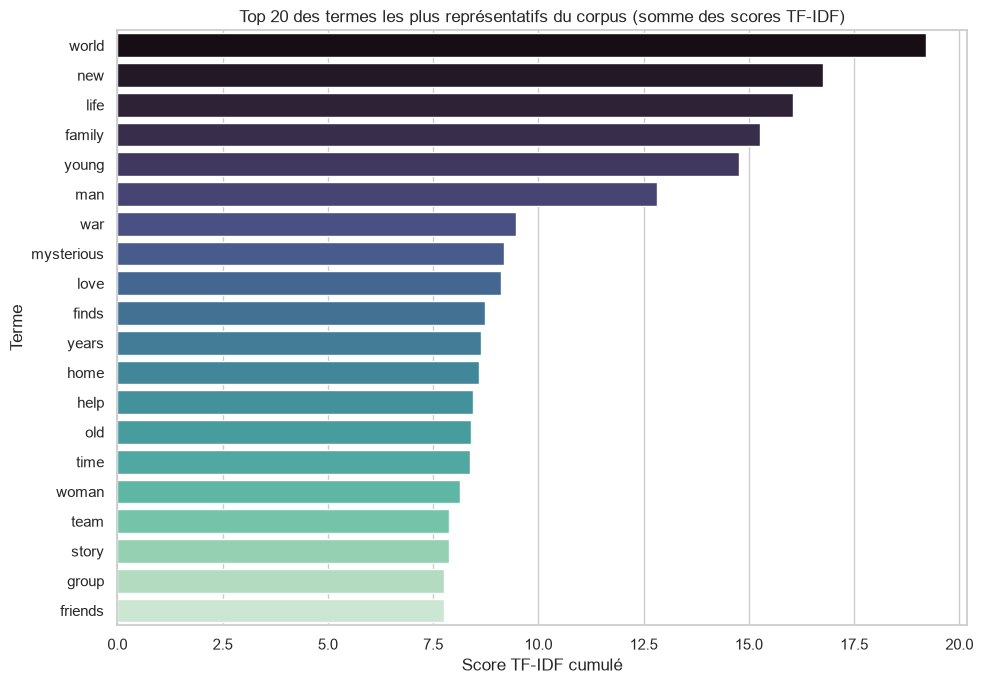

In [19]:
plt.figure(figsize=(10, 7))
sns.barplot(data=top_terms_df, x="score_tfidf_cumule", y="terme", palette="mako")
plt.title("Top 20 des termes les plus représentatifs du corpus (somme des scores TF-IDF)")
plt.xlabel("Score TF-IDF cumulé")
plt.ylabel("Terme")
plt.tight_layout()
plt.show()


**Interprétation :**
Ces termes dominants reflètent le vocabulaire le plus partagé à travers les synopsis — typiquement des mots très génériques au cinéma ("life", "story", "world", "young", "family", "new") plutôt que des mots rares mais très spécifiques à un seul film. C'est attendu : le score global favorise la fréquence d'usage à travers le corpus, pas la spécificité. Pour identifier ce qui distingue *un film en particulier*, il faut regarder le document individuellement plutôt que le score global.


In [20]:
def top_terms_for_movie(row_idx, n=8):
    row = X_final[row_idx].toarray().ravel()
    top_idx = row.argsort()[::-1][:n]
    top_idx = [i for i in top_idx if row[i] > 0]
    return list(zip(feature_names[top_idx], row[top_idx].round(3)))

sample_indices = df[df["has_overview"] == 1].sample(3, random_state=42).index

for idx in sample_indices:
    print(f"--- {df.loc[idx, 'title']} ---")
    for term, score in top_terms_for_movie(idx):
        print(f"   {term:<25} {score}")
    print()


--- Ghost Rider ---
   johnny                    0.659
   mephistopheles            0.349
   soul                      0.266
   order save                0.165
   hearted                   0.165
   rider                     0.158
   fiery                     0.158
   dying                     0.158

--- The Idea of You ---
   ne                        0.362
   hayes                     0.362
   romance                   0.325
   year old                  0.244
   year                      0.226
   old                       0.207
   mom                       0.173
   moon                      0.173

--- The Novices ---
   mona lisa                 0.437
   mona                      0.437
   lisa                      0.437
   profession                0.206
   refuge                    0.198
   novice                    0.198
   absolutely                0.198
   paris                     0.176



**Interprétation :**
Contrairement aux termes globaux, les termes les mieux notés *pour un film donné* sont beaucoup plus spécifiques à son intrigue — c'est exactement l'intérêt de TF-IDF : un mot qui apparaît souvent dans un synopsis donné **mais rarement ailleurs dans le corpus** reçoit un score élevé (poids IDF fort). C'est ce qui rend cette représentation utile pour comparer des films entre eux (similarité cosinus) ou pour un système de recommandation basé sur le contenu.


## 8. Synthèse

- **Valeurs manquantes** : synopsis vides remplacés par une chaîne vide plutôt que supprimés, avec un flag `has_overview` pour les tracer.
- **Nettoyage** : minuscules + suppression ponctuation/chiffres + espaces multiples ; pas de stemming/lemmatisation pour rester simple, stop words gérés nativement par `TfidfVectorizer`.
- **`max_features`** : contrôle directement le nombre de colonnes de la matrice — un compromis entre richesse du vocabulaire et coût mémoire/calcul en aval.
- **`ngram_range`** : à `max_features` fixé, élargir la plage de n-grammes ne change pas la taille de la matrice mais change sa composition (plus d'expressions multi-mots, moins de mots isolés distincts).
- **Termes représentatifs** : les termes à score global élevé sont génériques (vocabulaire du cinéma en général) ; les termes à score élevé *par film* sont beaucoup plus discriminants — c'est cette seconde vue qui est utile pour la suite (similarité / recommandation).

**Configuration retenue pour la suite du projet** : `TfidfVectorizer(stop_words="english", max_features=3000, ngram_range=(1,2))` — bon compromis taille/richesse sémantique pour ~1000 documents.
